# Задание 1: активации, инициализации и сходимость

Исследуем базовую нейросеть (`BaseNetwork`) на данных FashionMNIST.

**План:**
1. Возьмём функции активации из задания (ReLU, tanh, identity + LeakyReLU)
2. Для шести способов инициализации весов (нулевая, константная, две случайные, Xavier, Kaiming), построим графики активаций и градиентов **по слоям** и покажем, какие инициализации дают стабильные значения
3. На примере FashionMNIST сравним сходимость обучения (оптимизатор SGD) для всех комбинаций: активация + инициализация

In [1]:
import os
import time
import warnings

warnings.filterwarnings("ignore", message="The pynvml package is deprecated")

import numpy as np
import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from matplotlib import pyplot as plt
import pandas as pd

%matplotlib inline

seed = 42
torch.manual_seed(seed)
np.random.seed(seed)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Используется устройство: {device}")

Используется устройство: cpu


## Данные: FashionMNIST

In [2]:
DATA_ROOT = os.path.join("..", "..", "data")

transform = transforms.ToTensor()
train_data = datasets.FashionMNIST(root=DATA_ROOT, train=True, download=True, transform=transform)
test_data = datasets.FashionMNIST(root=DATA_ROOT, train=False, download=True, transform=transform)

print("Размер обучающей выборки:", len(train_data))
print("Размер тестовой выборки:", len(test_data))

test_loader = DataLoader(test_data, batch_size=1000, shuffle=False)

Размер обучающей выборки: 60000
Размер тестовой выборки: 10000


## Модель: BaseNetwork

In [3]:
class BaseNetwork(nn.Module):
    def __init__(self, act_fn, input_size=784, num_classes=10, hidden_sizes=[512, 256, 256, 128]):
        """
        act_fn       - объект функции активации
        input_size   - размер входа (пиксели)
        num_classes  - число классов
        hidden_sizes - размеры скрытых слоёв
        """
        super().__init__()

        # Create the network based on the specified hidden sizes
        layers = []
        layer_sizes = [input_size] + hidden_sizes
        for layer_index in range(1, len(layer_sizes)):
            layers += [nn.Linear(layer_sizes[layer_index - 1], layer_sizes[layer_index]),
                       act_fn]
        layers += [nn.Linear(layer_sizes[-1], num_classes)]
        self.layers = nn.ModuleList(layers)

        self.config = {"act_fn": act_fn.__class__.__name__, "input_size": input_size,
                       "num_classes": num_classes, "hidden_sizes": hidden_sizes}

    def forward(self, x):
        x = x.view(x.size(0), -1)
        for l in self.layers:
            x = l(x)
        return x


def get_activation(name):
    if name == "relu":
        return nn.ReLU()
    if name == "tanh":
        return nn.Tanh()
    if name == "identity":
        return nn.Identity()
    if name == "leaky_relu":
        return nn.LeakyReLU()
    raise ValueError(f"Неизвестная активация: {name}")


ACTIVATIONS = ["relu", "tanh", "identity", "leaky_relu"]
ACTIVATION_TITLES = {
    "relu": "ReLU",
    "tanh": "tanh",
    "identity": "identity (линейная)",
    "leaky_relu": "LeakyReLU",
}

## Способы инициализации весов

Реализуем шесть вариантов (смещения везде обнуляем):

| Имя | Что делает |
|-----|------------|
| `zeros` | все веса = 0 (вырожденный случай) |
| `constant` | все веса = 0.01 (маленькая константа) |
| `normal` | случайные веса из N(0, 1) - «крупная случайная» инициализация |
| `normal_small` | случайные веса из N(0, 0.01) - «малая случайная» |
| `xavier` | Xavier/Glorot: дисперсия подбирается под размеры слоя |
| `kaiming` | Kaiming/He - вариант, популярный для ReLU-сетей |

In [4]:
def apply_init(model, init_name, generator=None):
    """Применяет выбранную инициализацию ко всем линейным слоям модели"""
    for layer in model.layers:
        if not isinstance(layer, nn.Linear):
            continue
        with torch.no_grad():
            if init_name == "zeros":
                layer.weight.zero_()
            elif init_name == "constant":
                layer.weight.fill_(0.01)
            elif init_name == "normal":
                layer.weight.normal_(mean=0.0, std=1.0, generator=generator)
            elif init_name == "normal_small":
                layer.weight.normal_(mean=0.0, std=0.01, generator=generator)
            elif init_name == "xavier":
                nn.init.xavier_uniform_(layer.weight, gain=1.0, generator=generator)
            elif init_name == "kaiming":
                nn.init.kaiming_uniform_(layer.weight, a=0.0, mode="fan_in",
                                         nonlinearity="relu", generator=generator)
            else:
                raise ValueError(f"Неизвестная инициализация: {init_name}")
            layer.bias.zero_()

INITS = ["zeros", "constant", "normal", "normal_small", "xavier", "kaiming"]

## Эксперимент А: активации и градиенты по слоям

**Методика.** Для каждой пары (активация + инициализация):
1. Создаём новый экземпляр сети и инициализируем веса
2. Прогоняем **один и тот же фиксированный батч** из 256 картинок - прямой проход
3. Считаем по каждому слою статистики активаций (среднее значение по модулю, стандартное отклонение, доля нулей)
4. Делаем обратный проход от функции потерь (CrossEntropy) и собираем норму градиента весов каждого слоя

Так мы увидим, как сигнал (вперёд) и градиент (назад) доходят до каждого слоя при разных комбинациях

In [5]:
# Фиксированный батч для всех конфигураций
fixed_loader = DataLoader(train_data, batch_size=256, shuffle=False)
xb_fixed, yb_fixed = next(iter(fixed_loader))
print("Батч для анализа:", xb_fixed.shape, yb_fixed.shape)


def run_analysis_config(act_name, init_name, xb, yb, generator):
    """Считает статистики активаций и градиентов по слоям для одной конфигурации"""
    torch.manual_seed(seed)
    model = BaseNetwork(get_activation(act_name))
    apply_init(model, init_name, generator=generator)
    model.train()

    x = xb.to(device)
    y = yb.to(device)

    # Прямой проход с запоминанием активаций на выходе каждого линейного слоя
    activations = []
    h = x.view(x.size(0), -1)
    for layer in model.layers:
        h = layer(h)
        if isinstance(layer, nn.Linear):
            activations.append(h.detach())

    loss = F.cross_entropy(h, y)

    # Обратный проход
    model.zero_grad()
    loss.backward()

    # Статистики по слоям
    linear_layers = [l for l in model.layers if isinstance(l, nn.Linear)]
    stats = []
    samples = []
    for act_tensor, layer in zip(activations, linear_layers):
        stats.append({
            "act_mean_abs": act_tensor.abs().mean().item(),
            "act_std": act_tensor.std().item(),
            "act_frac_zero": (act_tensor == 0).float().mean().item(),
            "grad_norm": layer.weight.grad.norm().item(),
            "grad_mean_abs": layer.weight.grad.abs().mean().item(),
        })
        samples.append(act_tensor.flatten().cpu().numpy()[:20000]) # Небольшая подвыборка значений для гистограмм
    return stats, samples

Батч для анализа: torch.Size([256, 1, 28, 28]) torch.Size([256])


In [6]:
analysis = {}  # (активация, инициализация) -> {"stats": [...], "samples": [...]}

print(f"{'активация':<12} {'инициализация':<13} {'акт[1]':>10} {'акт[5]':>10} "
      f"{'град[1]':>10} {'град[5]':>10}  {'разброс акт':>12} {'град[1]/град[5]':>16}")

for act_name in ACTIVATIONS:
    for init_name in INITS:
        generator = torch.Generator().manual_seed(seed)
        stats, samples = run_analysis_config(act_name, init_name, xb_fixed, yb_fixed, generator)
        analysis[(act_name, init_name)] = {"stats": stats, "samples": samples}

        act_vals = [s["act_mean_abs"] for s in stats]
        grad_vals = [s["grad_norm"] for s in stats]
        spread_act = max(act_vals) / max(min(act_vals), 1e-300)
        grad_ratio = grad_vals[0] / max(grad_vals[-1], 1e-300)

        print(f"{act_name:<12} {init_name:<13} {act_vals[0]:>10.2e} {act_vals[-1]:>10.2e} "
              f"{grad_vals[0]:>10.2e} {grad_vals[-1]:>10.2e}  {spread_act:>12.2e} {grad_ratio:>16.2e}")

активация    инициализация     акт[1]     акт[5]    град[1]    град[5]   разброс акт  град[1]/град[5]
relu         zeros           0.00e+00   0.00e+00   0.00e+00   0.00e+00      0.00e+00         0.00e+00
relu         constant        2.27e+00   9.77e+01   1.45e-06   7.34e+01      4.29e+01         1.98e-08
relu         normal          1.01e+01   1.06e+05   4.62e+04   7.05e+04      1.05e+04         6.56e-01
relu         normal_small    1.01e-01   1.06e-05   2.68e-04   1.89e-04      9.53e+03         1.42e+00
relu         xavier          3.85e-01   1.90e-01   7.83e-01   1.96e-01      2.02e+00         3.98e+00
relu         kaiming         4.95e-01   5.39e-01   2.00e+00   1.00e+00      1.15e+00         2.00e+00
tanh         zeros           0.00e+00   0.00e+00   0.00e+00   0.00e+00      0.00e+00         0.00e+00
tanh         constant        2.27e+00   1.26e+00   4.27e-13   3.86e-01      3.76e+00         1.11e-12
tanh         normal          1.01e+01   8.49e+00   6.73e+01   1.39e+00      2.03e+

### График 1. Средняя величина активаций по слоям

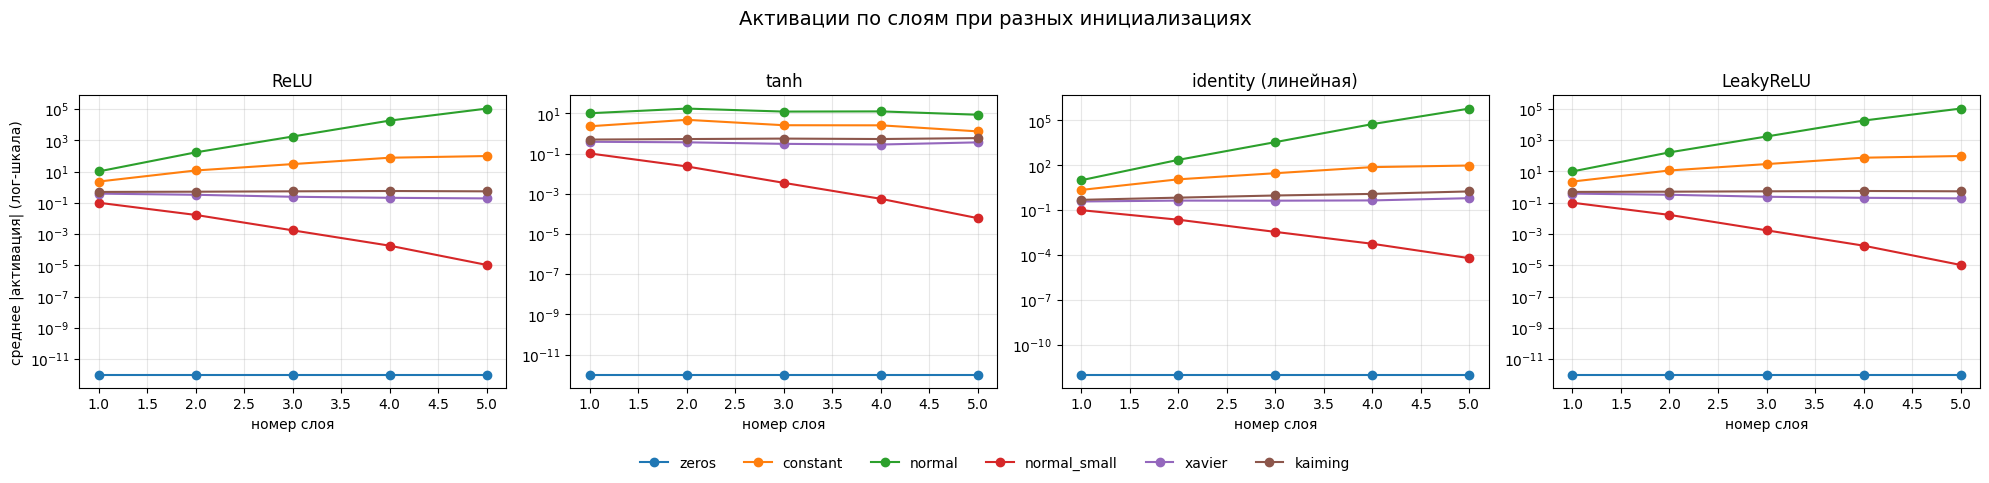

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.8), sharex=True)

for ax, act_name in zip(axes, ACTIVATIONS):
    for init_name in INITS:
        vals = [max(s["act_mean_abs"], 1e-12) for s in analysis[(act_name, init_name)]["stats"]]
        ax.plot(range(1, len(vals) + 1), vals, marker="o", label=init_name)
    ax.set_title(ACTIVATION_TITLES[act_name])
    ax.set_xlabel("номер слоя")
    ax.set_yscale("log")
    ax.grid(True, which="both", alpha=0.3)

axes[0].set_ylabel("среднее |активация| (лог-шкала)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=6, frameon=False)
fig.suptitle("Активации по слоям при разных инициализациях", fontsize=14)
fig.tight_layout(rect=(0, 0.07, 1, 0.95))
plt.show()

### График 2. Норма градиента весов по слоям

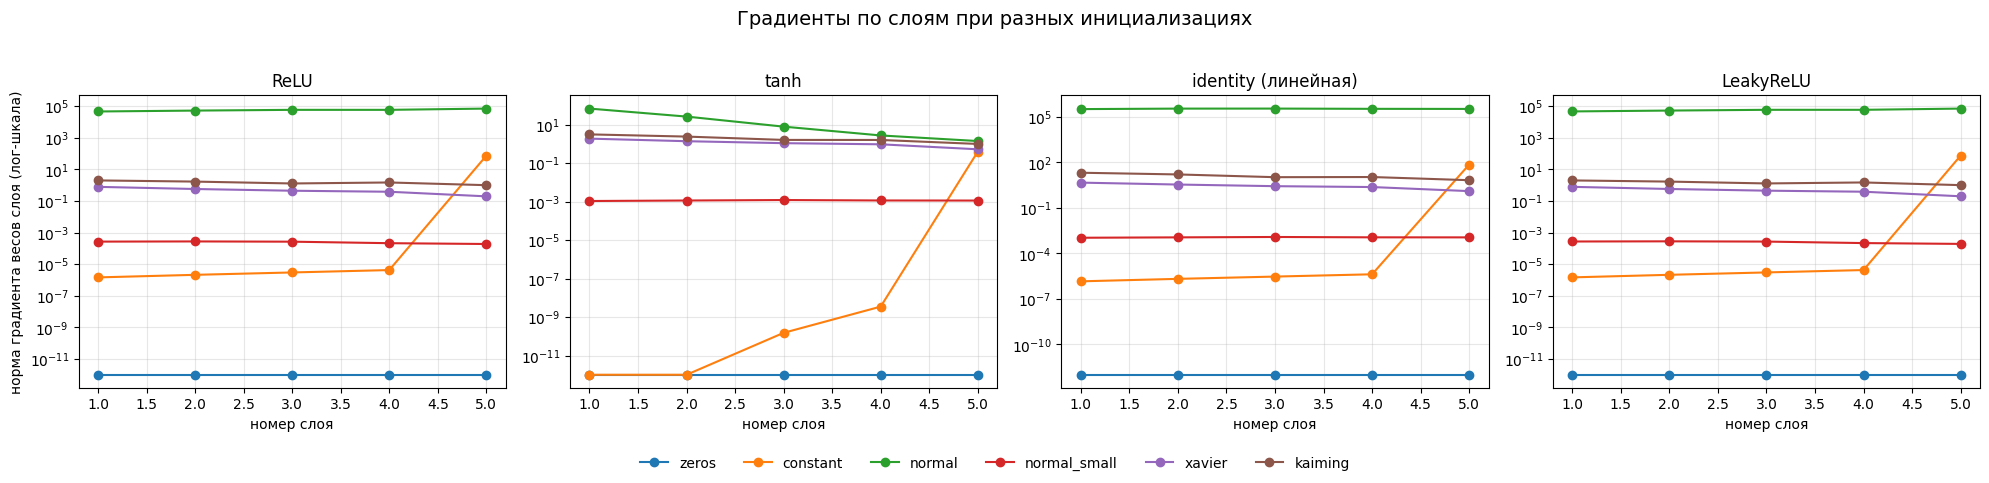

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.8), sharex=True)

for ax, act_name in zip(axes, ACTIVATIONS):
    for init_name in INITS:
        vals = [max(s["grad_norm"], 1e-12) for s in analysis[(act_name, init_name)]["stats"]]
        ax.plot(range(1, len(vals) + 1), vals, marker="o", label=init_name)
    ax.set_title(ACTIVATION_TITLES[act_name])
    ax.set_xlabel("номер слоя")
    ax.set_yscale("log")
    ax.grid(True, which="both", alpha=0.3)

axes[0].set_ylabel("норма градиента весов слоя (лог-шкала)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=6, frameon=False)
fig.suptitle("Градиенты по слоям при разных инициализациях", fontsize=14)
fig.tight_layout(rect=(0, 0.07, 1, 0.95))
plt.show()

### График 3. Распределения активаций по слоям

Для контраста сравниваем «крупную случайную» инициализацию `normal` (σ=1) с хорошей
`xavier`. Диапазон ограничен 1–99 перцентилями, чтобы выбросы не портили вид

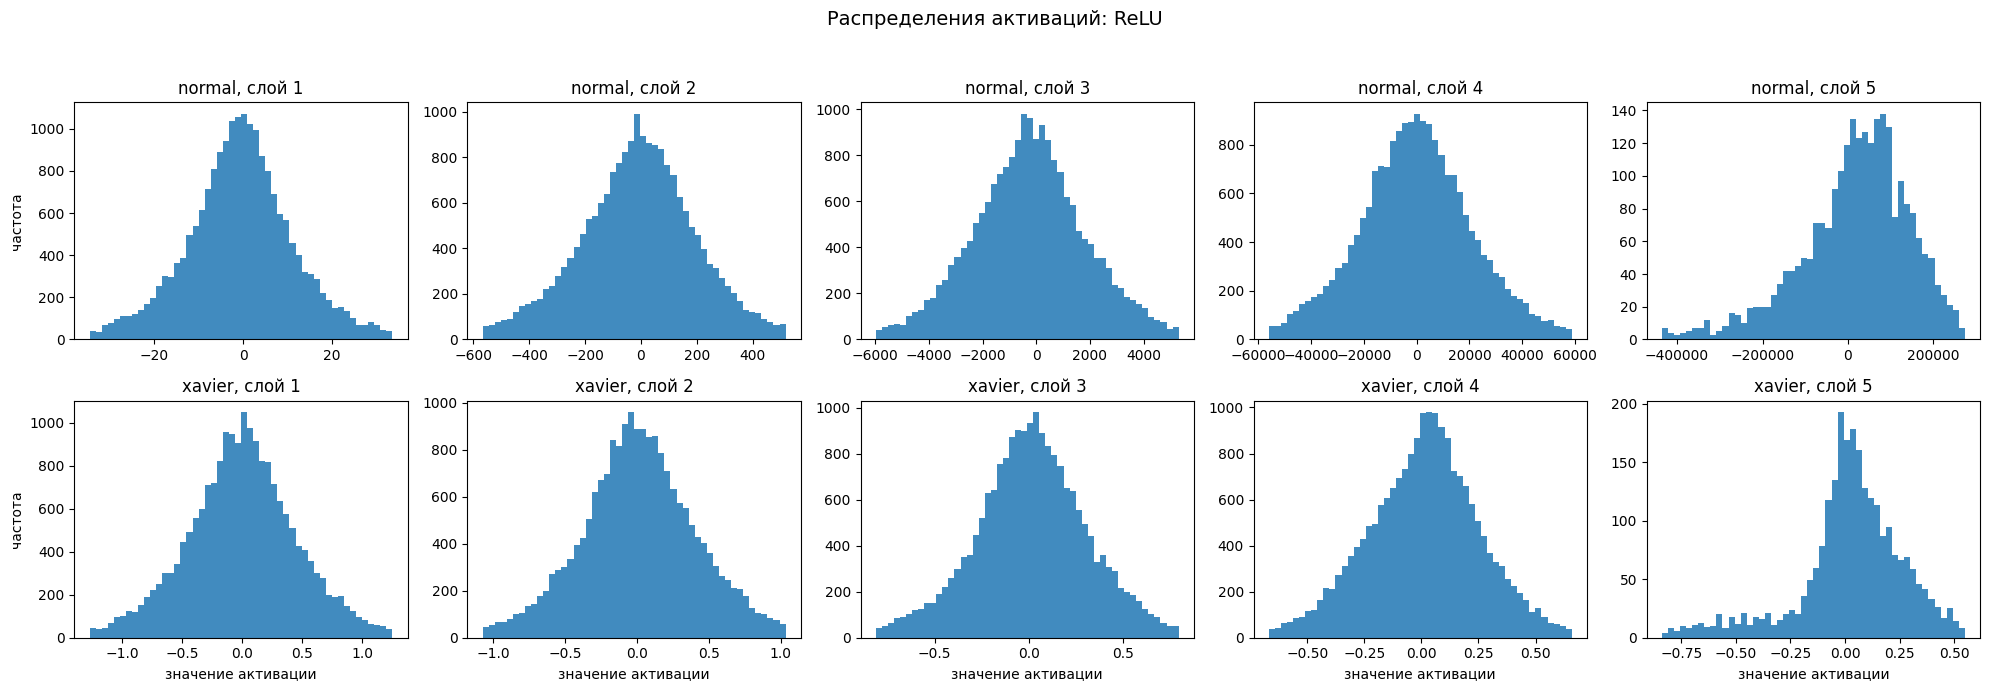

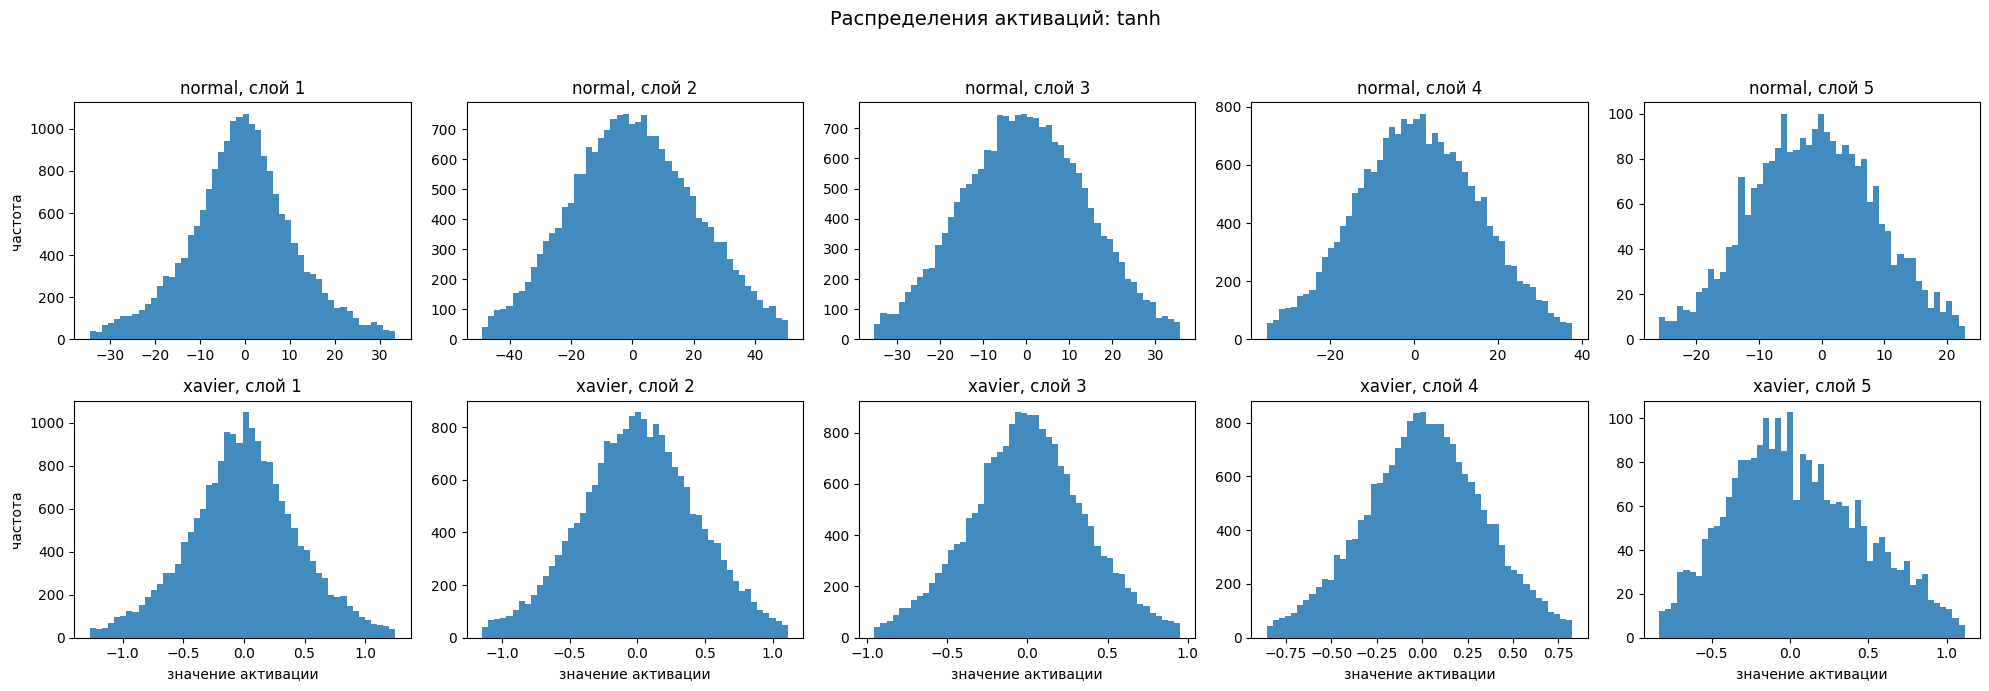

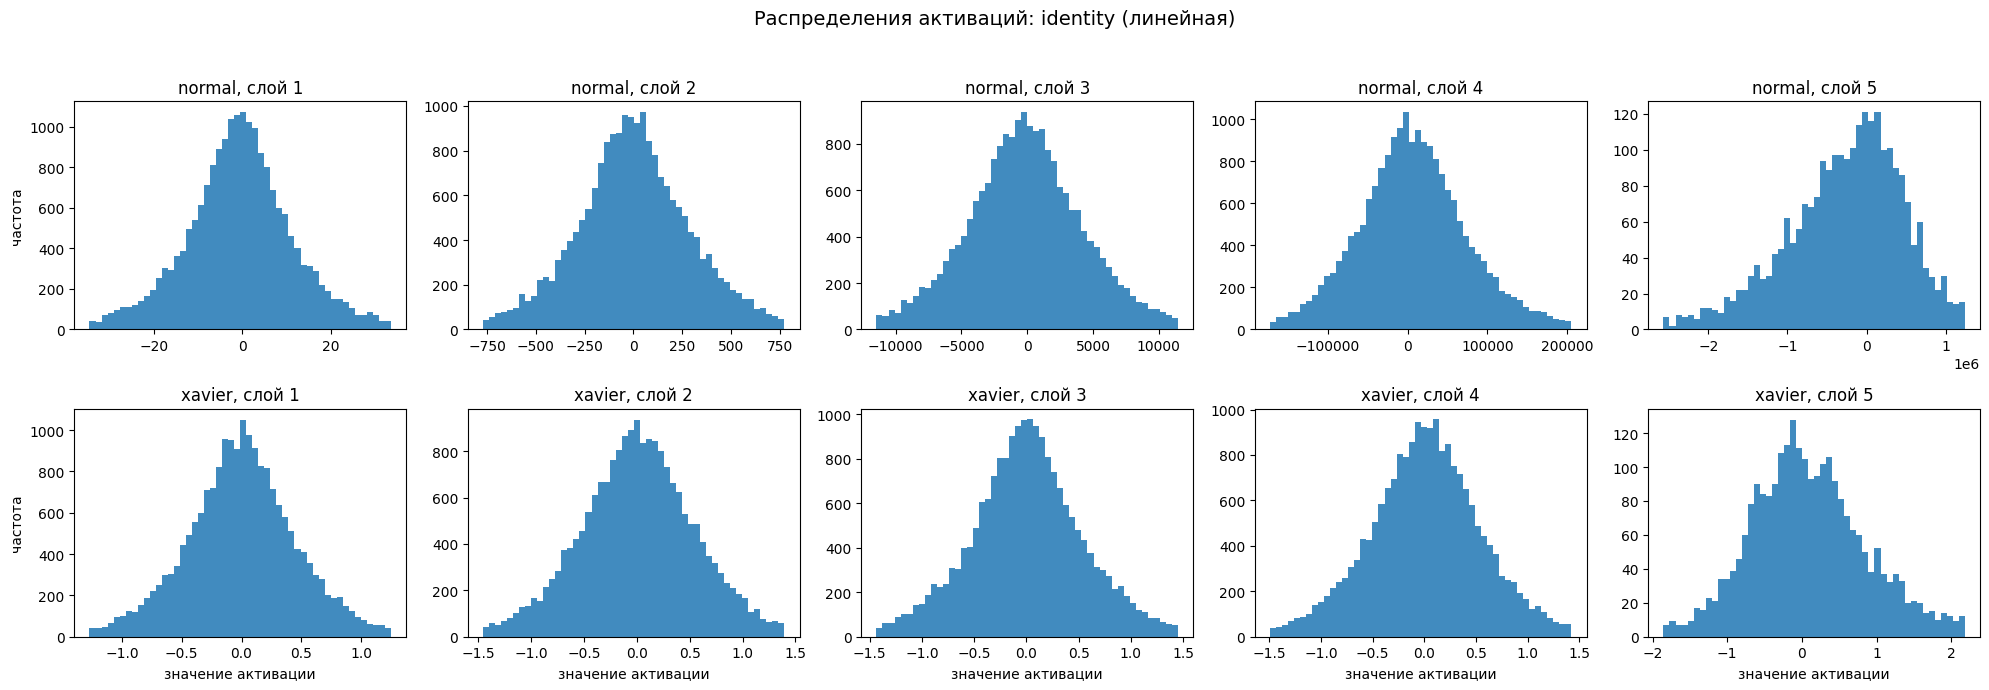

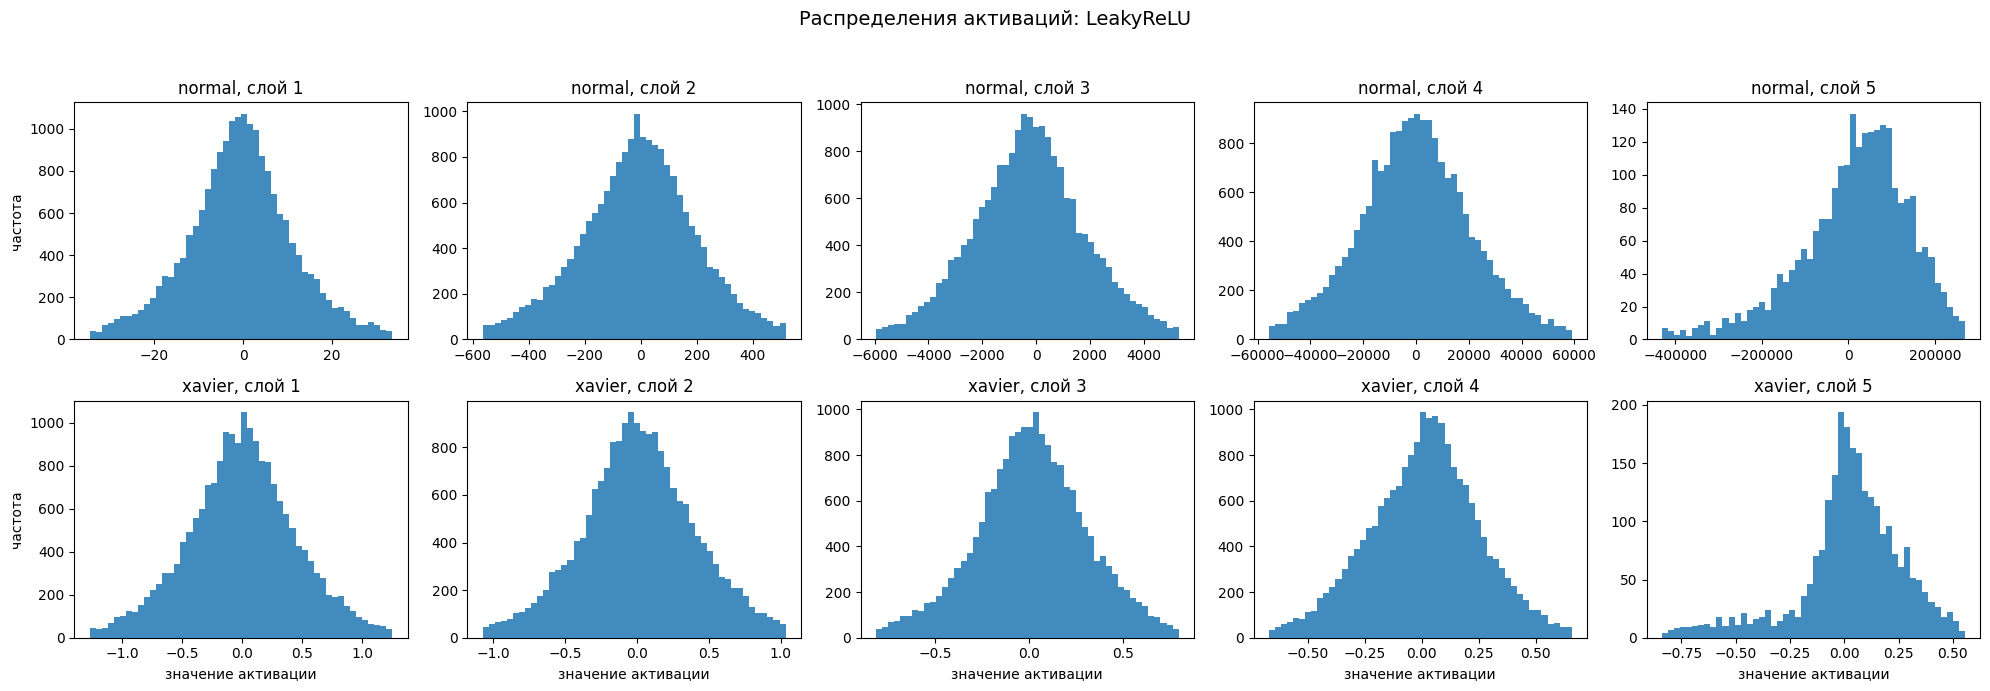

In [9]:
for act_name in ACTIVATIONS:
    fig, axes = plt.subplots(2, 5, figsize=(20, 7))
    for row, init_name in enumerate(["normal", "xavier"]):
        samples = analysis[(act_name, init_name)]["samples"]
        for col, layer_samples in enumerate(samples):
            ax = axes[row][col]
            lo, hi = np.percentile(layer_samples, [1, 99])
            if hi <= lo:
                lo, hi = lo - 1e-6, hi + 1e-6
            ax.hist(layer_samples, bins=50, range=(lo, hi), alpha=0.85)
            ax.set_title(f"{init_name}, слой {col + 1}")
            if row == 1:
                ax.set_xlabel("значение активации")
            if col == 0:
                ax.set_ylabel("частота")
    fig.suptitle(f"Распределения активаций: {ACTIVATION_TITLES[act_name]}", fontsize=14)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    plt.show()

## Эксперимент B: сравнение сходимости (оптимизатор SGD)

**План**: Обучаем сеть `BaseNetwork` при фиксированных условиях:
* Оптимизатор SGD, learning rate = 0.1 (одинаковый для всех запусков - сравниваем именно влияние активации и инициализации)
* Размер батча 256, 4 эпохи, полная обучающая выборка (60000 изображений)
* Порядок данных фиксирован (seed), поэтому все запуски видят одинаковые батчи
* Набор: 4 активации × 4 инициализации (нулевая, константная, крупная случайная, Xavier) = 16 запусков

In [10]:
EPOCHS_CONV = 4
BATCH_SIZE = 256
LR = 0.1

CONV_ACTS = ["relu", "tanh", "identity", "leaky_relu"]
CONV_INITS = ["zeros", "constant", "normal", "xavier"]


def train_model(act_name, init_name):
    """Обучает модель с заданной активацией и инициализацией"""
    torch.manual_seed(seed)
    model = BaseNetwork(get_activation(act_name)).to(device)
    generator = torch.Generator().manual_seed(seed)
    apply_init(model, init_name, generator=generator)

    loader_gen = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, generator=loader_gen)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=LR)

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    for epoch in range(EPOCHS_CONV):
        # Обучение
        model.train()
        total_loss = 0.0
        total_correct = 0
        total = 0
        for xb, yb in train_loader:
            xb = xb.to(device).view(xb.size(0), -1)
            yb = yb.to(device)
            optimizer.zero_grad()
            out = model(xb)
            loss = criterion(out, yb)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * xb.size(0)
            total_correct += (out.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)
        history["train_loss"].append(total_loss / total)
        history["train_acc"].append(total_correct / total)

        # Валидация
        model.eval()
        v_loss = 0.0
        v_correct = 0
        v_total = 0
        with torch.no_grad():
            for xb, yb in test_loader:
                xb = xb.to(device).view(xb.size(0), -1)
                yb = yb.to(device)
                out = model(xb)
                v_loss += criterion(out, yb).item() * xb.size(0)
                v_correct += (out.argmax(dim=1) == yb).sum().item()
                v_total += xb.size(0)
        history["val_loss"].append(v_loss / v_total)
        history["val_acc"].append(v_correct / v_total)

    return history

In [11]:
conv_results = {}

for act_name in CONV_ACTS:
    for init_name in CONV_INITS:
        t0 = time.time()
        history = train_model(act_name, init_name)
        conv_results[(act_name, init_name)] = history
        acc_line = ", ".join(f"{a:.3f}" for a in history["val_acc"])
        print(f"{act_name:<10} | {init_name:<8} | val_acc: {acc_line} | {time.time() - t0:.0f} с")

relu       | zeros    | val_acc: 0.100, 0.100, 0.100, 0.100 | 44 с
relu       | constant | val_acc: 0.100, 0.100, 0.100, 0.100 | 44 с
relu       | normal   | val_acc: 0.100, 0.100, 0.100, 0.100 | 44 с
relu       | xavier   | val_acc: 0.722, 0.833, 0.843, 0.856 | 44 с
tanh       | zeros    | val_acc: 0.100, 0.100, 0.100, 0.100 | 44 с
tanh       | constant | val_acc: 0.100, 0.100, 0.100, 0.100 | 45 с
tanh       | normal   | val_acc: 0.519, 0.602, 0.644, 0.665 | 44 с
tanh       | xavier   | val_acc: 0.742, 0.827, 0.841, 0.855 | 45 с
identity   | zeros    | val_acc: 0.100, 0.100, 0.100, 0.100 | 45 с
identity   | constant | val_acc: 0.100, 0.100, 0.100, 0.100 | 44 с
identity   | normal   | val_acc: 0.100, 0.100, 0.100, 0.100 | 45 с
identity   | xavier   | val_acc: 0.100, 0.100, 0.100, 0.100 | 44 с
leaky_relu | zeros    | val_acc: 0.100, 0.100, 0.100, 0.100 | 44 с
leaky_relu | constant | val_acc: 0.100, 0.100, 0.100, 0.100 | 44 с
leaky_relu | normal   | val_acc: 0.100, 0.100, 0.100, 0.100 | 

### График 4. Кривые обучения (train loss по эпохам)

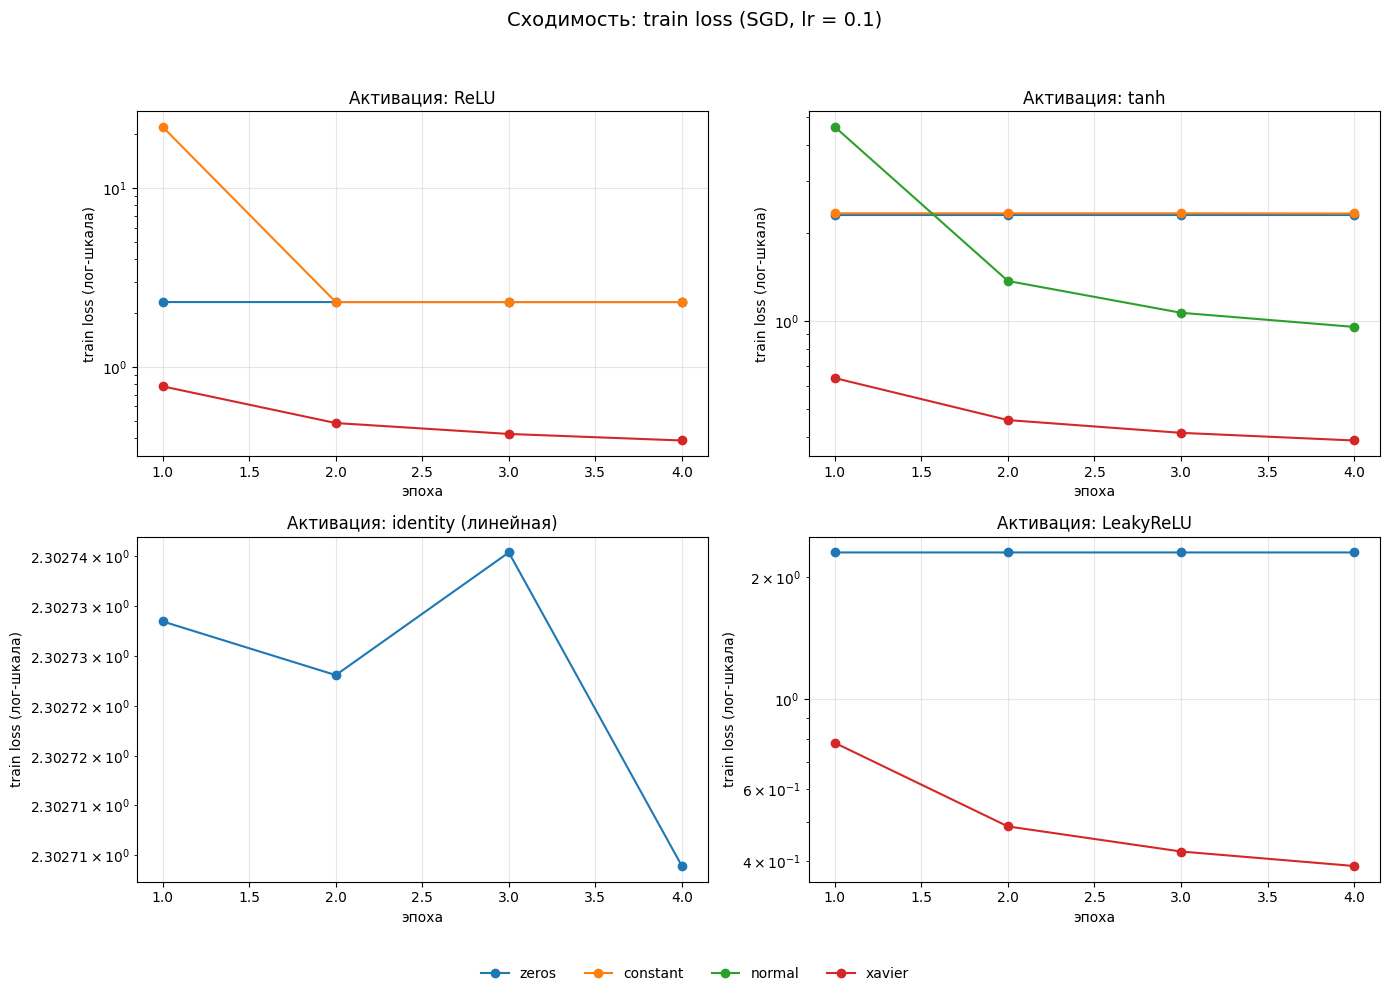

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, act_name in zip(axes.flatten(), CONV_ACTS):
    for init_name in CONV_INITS:
        history = conv_results[(act_name, init_name)]
        ax.plot(range(1, EPOCHS_CONV + 1), history["train_loss"], marker="o", label=init_name)
    ax.set_title(f"Активация: {ACTIVATION_TITLES[act_name]}")
    ax.set_xlabel("эпоха")
    ax.set_ylabel("train loss (лог-шкала)")
    ax.set_yscale("log")
    ax.grid(True, alpha=0.3)

handles, labels = axes[0][0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False)
fig.suptitle("Сходимость: train loss (SGD, lr = 0.1)", fontsize=14)
fig.tight_layout(rect=(0, 0.05, 1, 0.95))
plt.show()

### Рисунок 5. Валидационная точность по эпохам

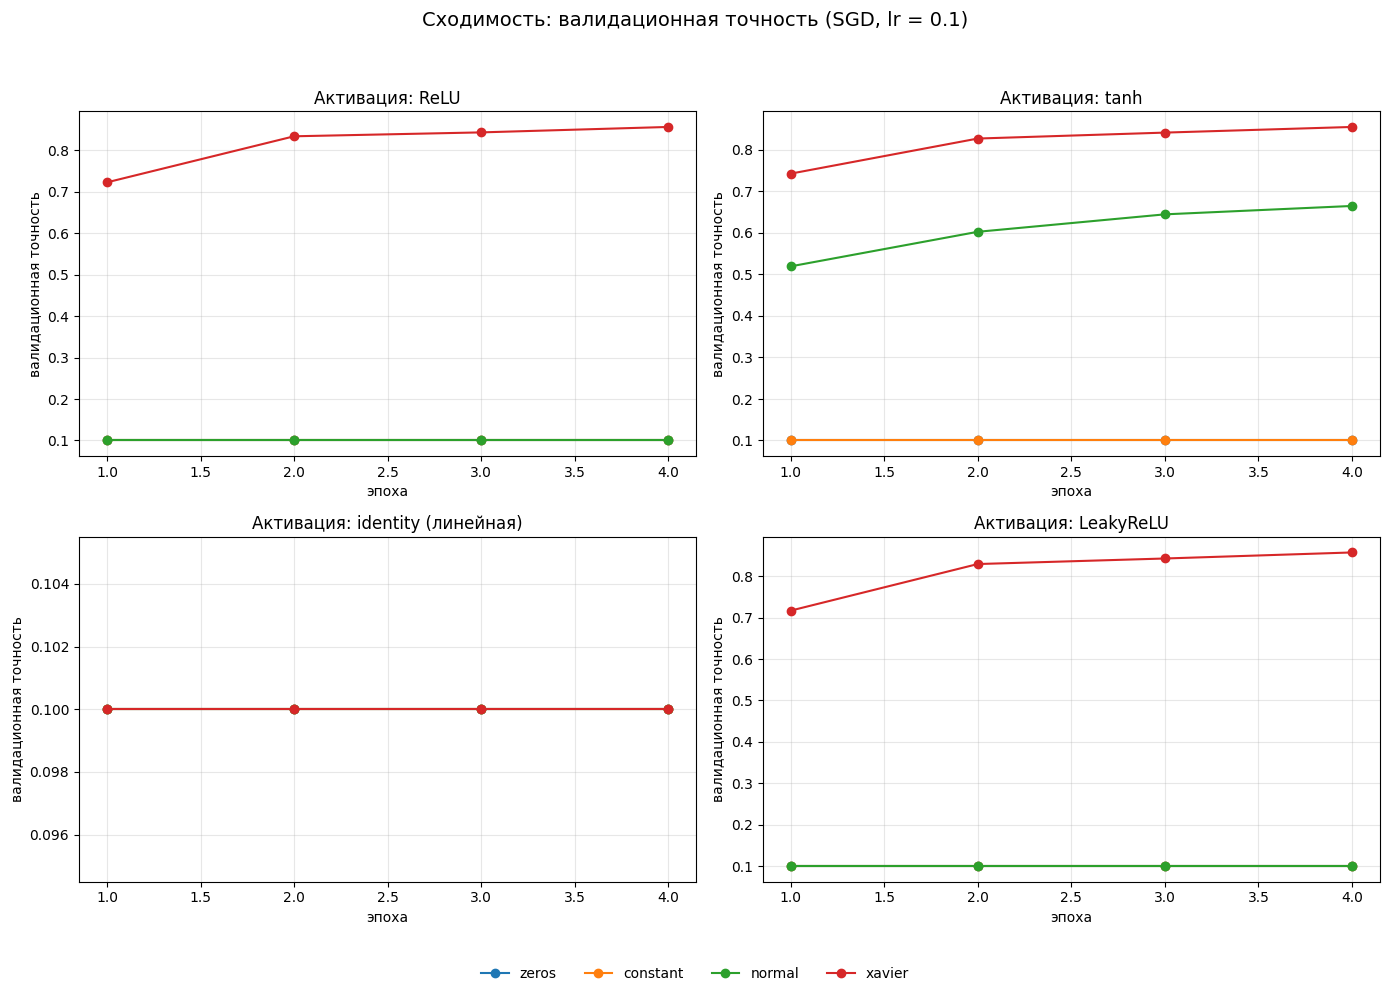

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, act_name in zip(axes.flatten(), CONV_ACTS):
    for init_name in CONV_INITS:
        history = conv_results[(act_name, init_name)]
        ax.plot(range(1, EPOCHS_CONV + 1), history["val_acc"], marker="o", label=init_name)
    ax.set_title(f"Активация: {ACTIVATION_TITLES[act_name]}")
    ax.set_xlabel("эпоха")
    ax.set_ylabel("валидационная точность")
    ax.grid(True, alpha=0.3)

handles, labels = axes[0][0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False)
fig.suptitle("Сходимость: валидационная точность (SGD, lr = 0.1)", fontsize=14)
fig.tight_layout(rect=(0, 0.05, 1, 0.95))
plt.show()

### Итоговая таблица по всем 16 запускам

In [14]:
rows = []
for (act_name, init_name), history in conv_results.items():
    rows.append({
        "активация": ACTIVATION_TITLES[act_name],
        "инициализация": init_name,
        "train_loss (эпоха 4)": history["train_loss"][-1],
        "val_loss (эпоха 4)": history["val_loss"][-1],
        "val_acc (эпоха 4)": history["val_acc"][-1],
    })

summary = pd.DataFrame(rows).sort_values("val_acc (эпоха 4)", ascending=False).reset_index(drop=True)
summary

,активация,инициализация,train_loss (эпоха 4),val_loss (эпоха 4),val_acc (эпоха 4)
0,LeakyReLU,xavier,0.388498,0.401321,0.8577
1,ReLU,xavier,0.387229,0.404781,0.8556
2,tanh,xavier,0.389230,0.410857,0.8548
3,tanh,normal,0.953152,0.943671,0.6646
4,ReLU,normal,NaN,NaN,0.1000
5,ReLU,constant,2.302709,2.302599,0.1000
6,tanh,constant,2.330335,2.342744,0.1000
7,ReLU,zeros,2.302709,2.302599,0.1000
8,tanh,zeros,2.302709,2.302599,0.1000
9,identity (линейная),zeros,2.302709,2.302599,0.1000


In [15]:
print("Лучшие 5 конфигураций:")
print(summary.head(5).to_string(index=False))
print()
print("Худшие 5 конфигураций:")
print(summary.tail(5).to_string(index=False))

Лучшие 5 конфигураций:
активация инициализация  train_loss (эпоха 4)  val_loss (эпоха 4)  val_acc (эпоха 4)
LeakyReLU        xavier              0.388498            0.401321             0.8577
     ReLU        xavier              0.387229            0.404781             0.8556
     tanh        xavier              0.389230            0.410857             0.8548
     tanh        normal              0.953152            0.943671             0.6646
     ReLU        normal                   NaN                 NaN             0.1000

Худшие 5 конфигураций:
          активация инициализация  train_loss (эпоха 4)  val_loss (эпоха 4)  val_acc (эпоха 4)
identity (линейная)      constant                   NaN                 NaN                0.1
identity (линейная)        xavier                   NaN                 NaN                0.1
          LeakyReLU         zeros              2.302709            2.302599                0.1
          LeakyReLU      constant                   NaN        

## Выводы

### Эксперимент А: активации и градиенты по слоям (Графики 1–3)

* **Нулевая инициализация** - вырожденный случай: все активации и градиенты равны нулю, и так остаётся для любой функции активации - сеть вообще не может обучаться (симметрия не нарушается).
* **Маленькие инициализации (`constant` 0.01 и `normal` σ=0.01)** - сигнал не доживает до глубоких слоёв: средняя активация падает с ~0.1 до ~1e-5 (разброс до ~9500 раз), градиенты тоже на порядки меньше «здоровых» значений. Модель практически не обучается.
* **Крупная случайная инициализация (N(0,1))** - противоположная беда: активации и градиенты раздуваются с глубиной (до ~1e5–6e5 и ~3e5). Для ReLU/LeakyReLU/identity обучение расходится (NaN); для tanh пред-активации уходят в насыщение (по модулю ~10, tanh ≈ ±1), масштаб градиентов по слоям перекашивается (~50 раз), и сеть учится плохо.
* **Xavier и Kaiming - самые устойчивые**: величины активаций и градиентов меняются по слоям плавно (разброс активаций ≈ 1.2–3.7, изменение градиентов ≈ 2–4 раза), без взрывов и затуханий на порядки.
* Ответ на вопрос задания: **стабильные активации и градиенты даёт масштабированная инициализация (Xavier/Kaiming)** - для ReLU/LeakyReLU лучше Kaiming (или Xavier), для tanh - Xavier; константные и слишком маленькие/большие инициализации приводят либо к вырождению, либо к взрыву/затуханию сигнала. Для identity устойчивой инициализации нет - линейная сеть расходится.

_(Примечание: нормы градиентов - это норма всей матрицы градиентов слоя; размеры слоёв разные, поэтому сравниваем порядки величин и их изменение от слоя к слою.)_

### Эксперимент B: сходимость (SGD, lr = 0.1, 4 эпохи) (Графики 4–5)

* Лучшие конфигурации - **Xavier + (LeakyReLU / ReLU / tanh)**: валидационная точность **0.855–0.858** за 4 эпохи. Активация **LeakyReLU** дала лучший результат (0.8577); ReLU - 0.8556, tanh - 0.8548.
* tanh с крупной случайной инициализацией учится заметно хуже (0.665) - часть нейронов сразу в насыщении.
* **identity (линейная сеть) расходится при всех инициализациях** (NaN): глубокая сеть без нелинейности неустойчива, поэтому нелинейность принципиально важна. Отдельная проверка подтвердила: NaN в весах появляется в пределах первых ~150 шагов обучения.
* Константная и нулевая инициализации не обучаются вообще: точность 0.100 (уровень случайного угадывания), лосс застревает на уровне ln 10 ≈ 2.303. Крупная случайная инициализация тоже расходится.
* Общий вывод: **решающий фактор - масштаб весов**. Работоспособны только инициализации, сохраняющие дисперсию сигнала по слоям (Xavier/Kaiming); для этой сети влияние инициализации оказалось даже сильнее, чем выбор активации из рассмотренных.